615 coins, 188,805 coin pairs
Dependence measures: ['pearson', 'lower_tail', 'bear_day_corr']
Train-period matrices not found: the out-of-sample parts will be skipped.
Build them first with points_2_to_5.py (cell 2c) to enable them.
                  min  median     max     std  share_at_modal_value
Copula         0.0000  0.4023  1.0012  0.1624                0.0435
HMM           -0.9451  0.7304  1.0000  0.3065                0.0333
GLASSO         0.4481  0.5000  0.6707  0.0030                0.9828
DTW            0.2863  0.3679  1.0000  0.0432                0.0001
Cointegration  0.0000  0.0103  1.0000  0.0067                0.0506


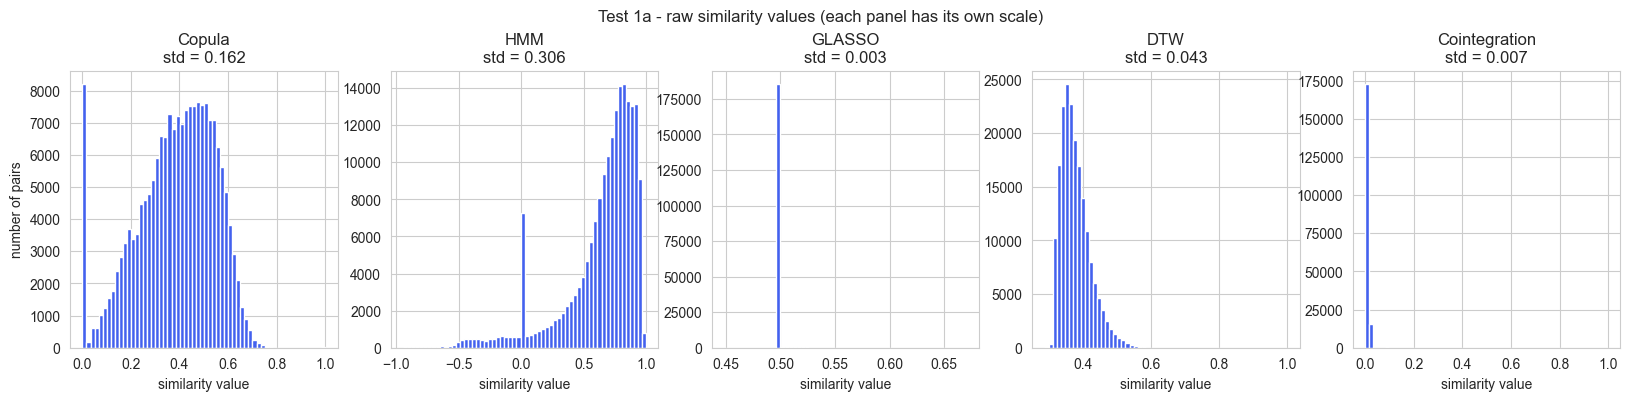


Spearman correlation between the combined score and each method:
               plain average of raw values  Borda (rank average)
Copula                               0.820                 0.831
HMM                                  0.805                 0.660
GLASSO                               0.100                 0.153
DTW                                  0.726                 0.799
Cointegration                        0.246                 0.524


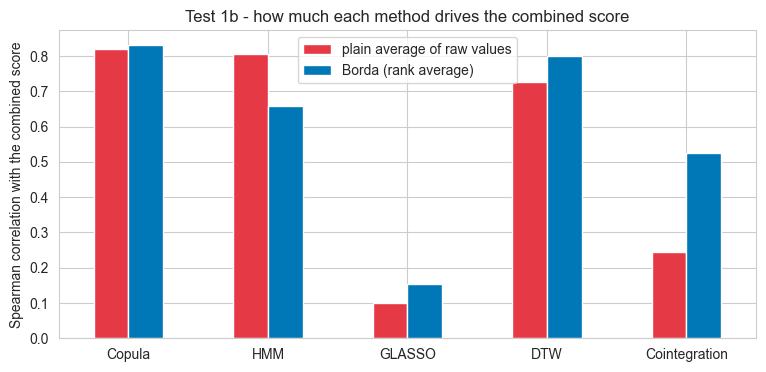


Spread of influence (max - min): plain average 0.720, Borda 0.679
Nearly constant matrices (more than half of the pairs share one value): GLASSO.
Ranking cannot separate tied pairs, so these methods have little real influence even at weight 1/5.
Max absolute difference vs saved composite: 2.93e-04
WARNING - the saved composite was built differently.


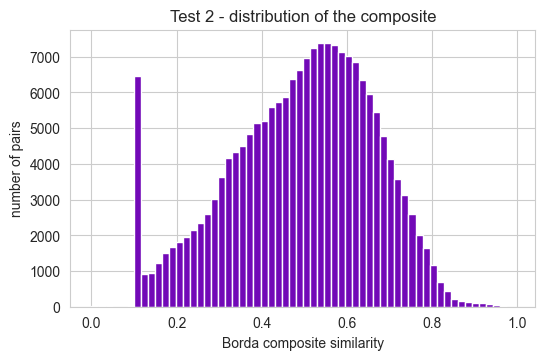

Recomputed Borda groups vs thesis file, ARI = 1.000
3a / 3b  In-sample (full period)

Drop-one-method results:
                    ari_vs_equal  gap_pearson  gap_lower_tail  gap_bear_day_corr
weights                                                                         
equal                     1.0000       0.0750          0.0955             0.0683
drop Copula               0.3961       0.0639          0.0475             0.0612
drop HMM                  0.5645       0.0491          0.1070             0.0580
drop GLASSO               0.3968       0.0785          0.0604             0.0693
drop DTW                  0.3207       0.0513          0.0597             0.0657
drop Cointegration        0.5181       0.0997          0.1389             0.0905

Random weights - where do equal weights sit? (share of random sets with a lower gap, and share with the same gap)
  gap_pearson          equal 0.0750 | random: min -0.0078, median 0.0772, max 0.1501 | equal beats 48%, ties 0% of random sets

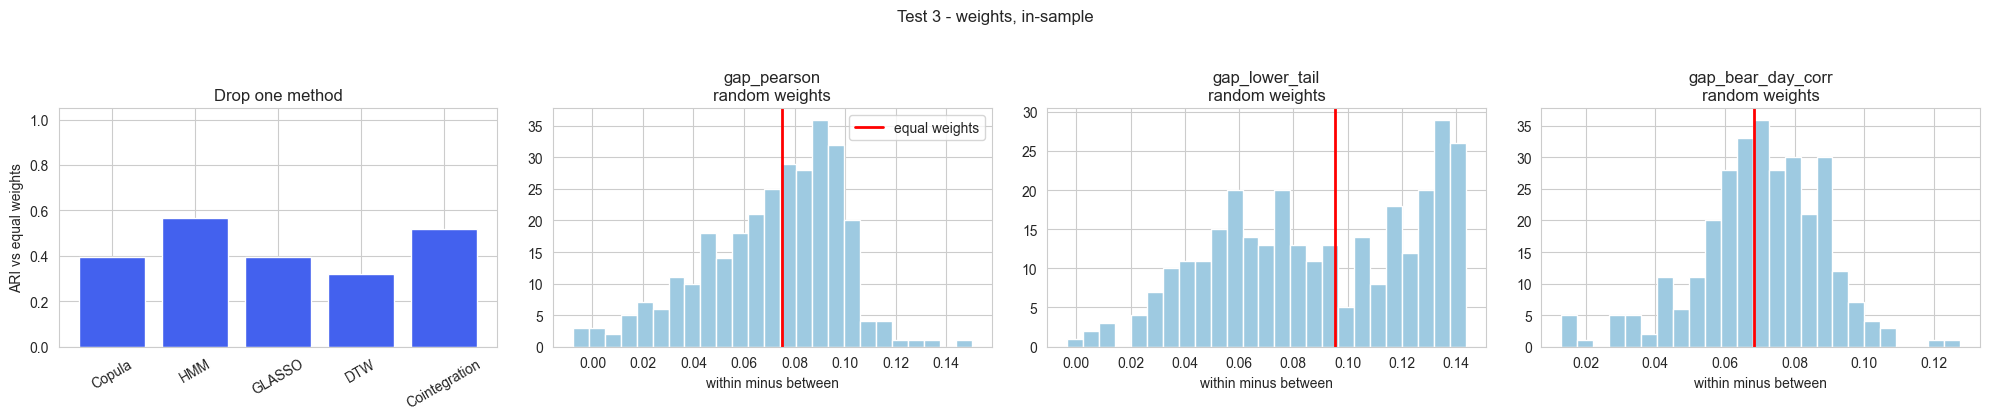


3c skipped (no train-period matrices).
Evidence accumulation with 45 groupings. The data prefers K = 3 (largest dendrogram jump).

Number of pairs by how many of the 5 methods put them together:
0     9938
1    40670
2    62898
3    48540
4    21519
5     5240


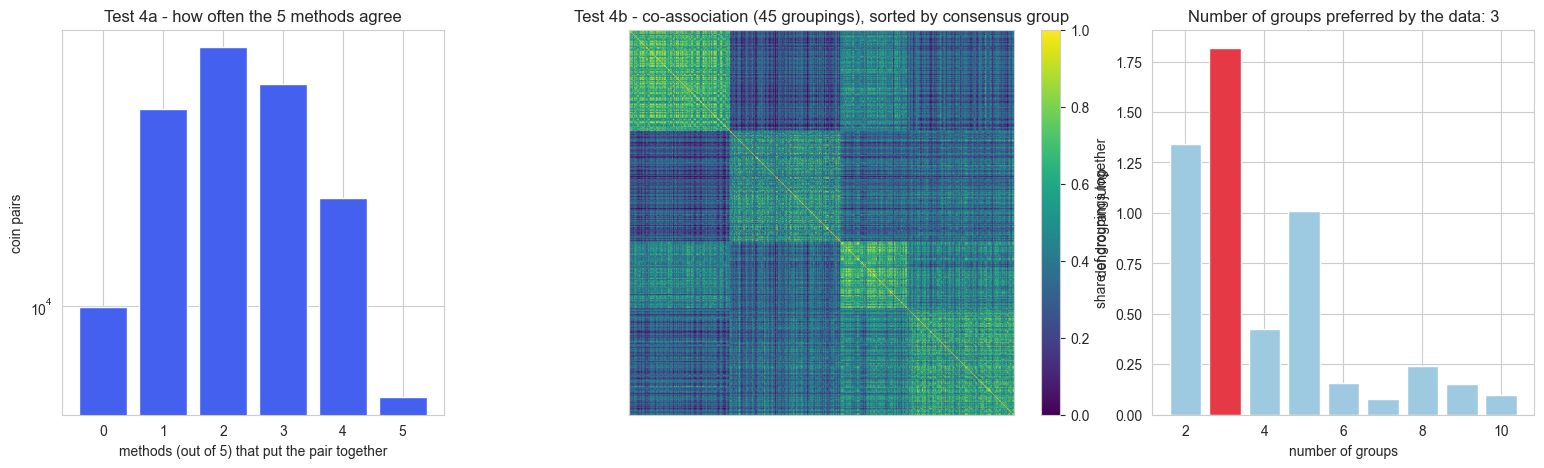

Z-score average vs Borda     ARI = 0.533
Z-score cluster sizes: [252, 215, 117, 31]


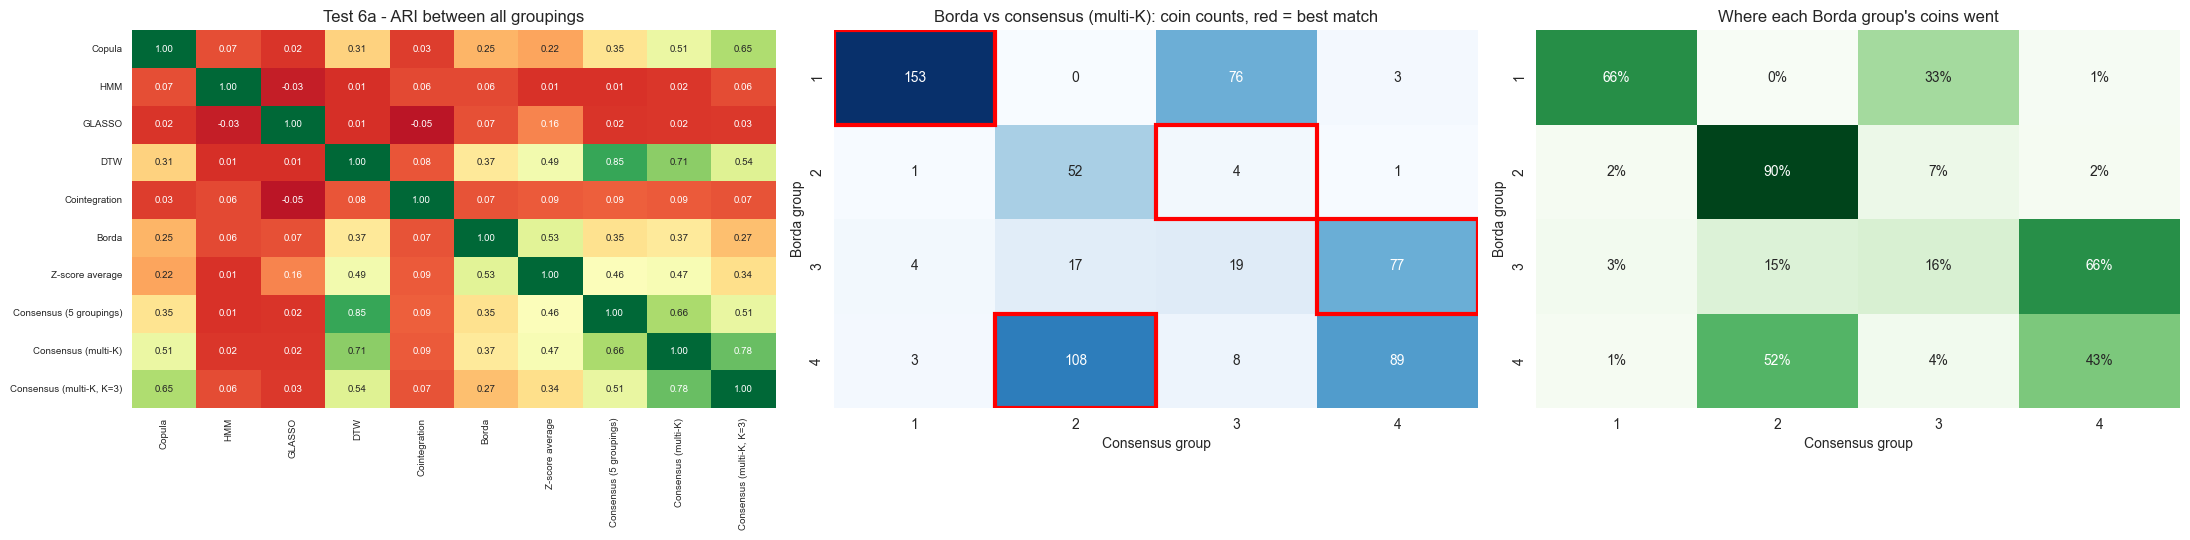

Borda vs Consensus (5 groupings) ARI  = 0.351
Borda vs Consensus (multi-K, K=4) ARI = 0.373
Coins in a matched Borda/consensus group: 56%

Borda vs consensus ARI for different K:
 K  ARI_vs_consensus_5  ARI_vs_consensus_multiK
 2               0.762                    0.507
 3               0.275                    0.303
 4               0.351                    0.373
 5               0.236                    0.299
 6               0.242                    0.300
 7               0.262                    0.281
 8               0.232                    0.226
 9               0.220                    0.223
10               0.198                    0.214

Running 50 coin subsamples (a few minutes)...
Subsample ARI, Borda vs consensus (5):     mean 0.328, 95% [0.187, 0.466]
Subsample ARI, Borda vs consensus (multi-K): mean 0.370, 95% [0.234, 0.521]


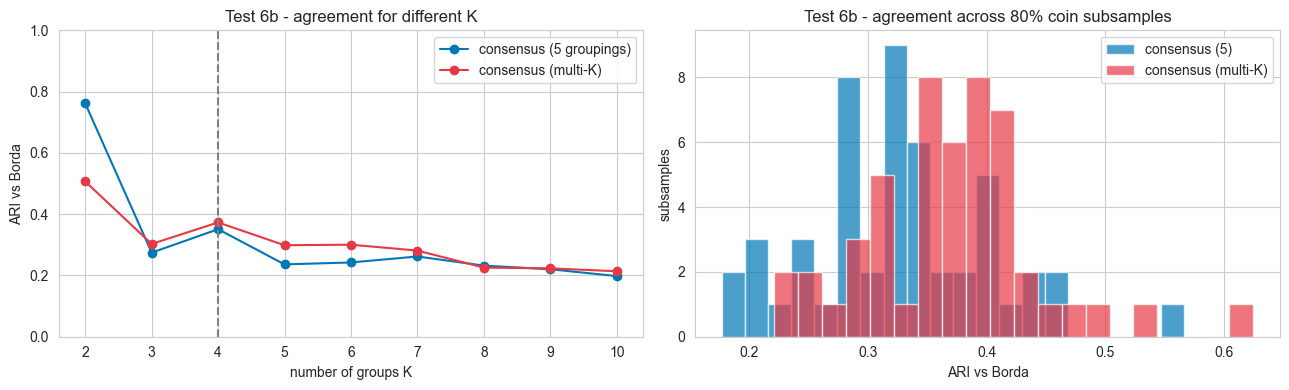

IN-SAMPLE gap (within minus between):
measure                  bear_day_corr  lower_tail  pearson
clustering                                                 
Borda (equal weights)           0.0683      0.0955   0.0750
Cointegration only              0.0028     -0.0220  -0.0116
Consensus (5 groupings)         0.0399      0.0419  -0.0007
Consensus (multi-K)             0.0590      0.0615   0.0231
Copula only                     0.0961      0.1186   0.1087
DTW only                        0.0516      0.0521   0.0102
GLASSO only                     0.0252      0.0480   0.0234
HMM only                        0.0532      0.0222   0.0748
Z-score average                 0.0411      0.0663   0.0230

Permutation p-values:
measure                  bear_day_corr  lower_tail  pearson
clustering                                                 
Borda (equal weights)           0.0050       0.005   0.0050
Cointegration only              0.3284       1.000   0.9652
Consensus (5 groupings)         0.0050 

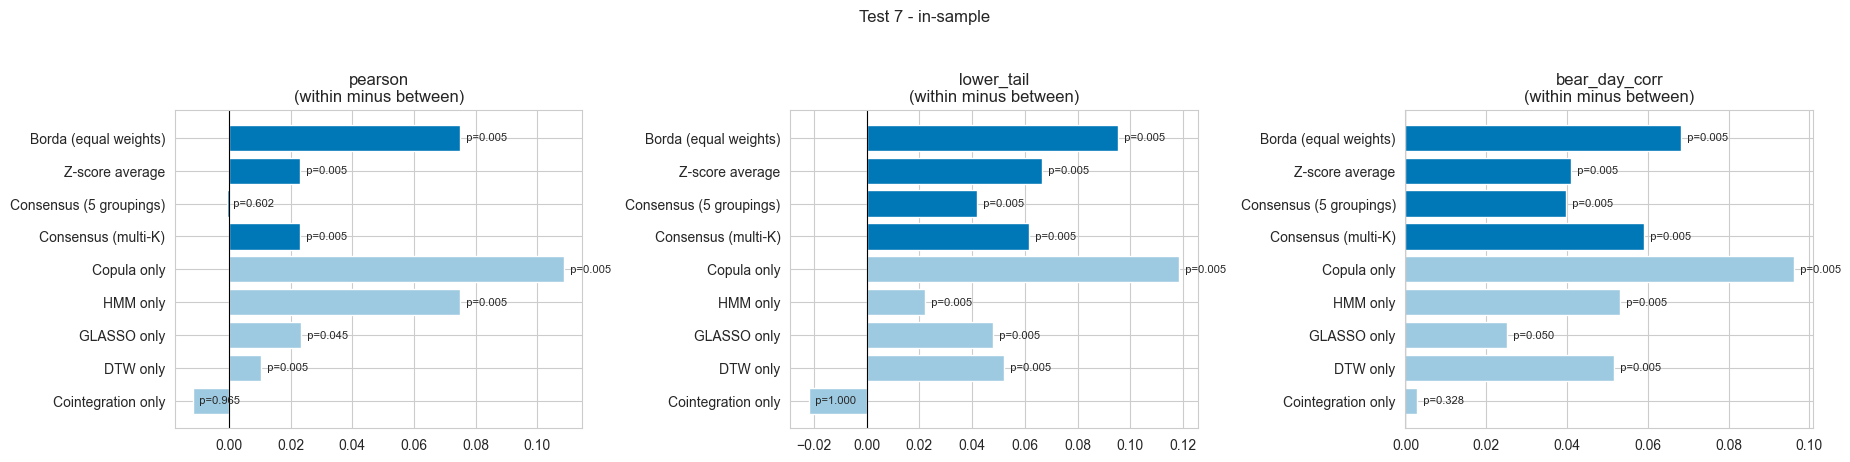


Out-of-sample part skipped (no train-period matrices).
SUMMARY FOR POINT 1

1. Scales: std of the five matrices ranges from 0.003 to 0.306.
   Nearly constant (tied) matrices: GLASSO.
2. Borda reproduced from the five matrices, max difference 2.9e-04.
3. Weights (in-sample): dropping one method gives ARI vs equal weights from 0.32 (drop DTW) to 0.56 (drop HMM).
   Random weights: median ARI 0.44; on pearson equal weights beat 48% and tie 0% of random sets, on lower_tail equal weights beat 56% and tie 0% of random sets, on bear_day_corr equal weights beat 43% and tie 0% of random sets.
4. Consensus: the data prefers K = 3 groups; at K = 4 Borda vs consensus ARI is 0.35 (5 groupings) and 0.37 (multi-K).
   Across K = 2..10 the multi-K ARI ranges from 0.21 to 0.51; across subsamples it averages 0.37.
5. Z-score average vs Borda ARI = 0.53.
7. Conclusions in-sample (combined versions with gap > 0 and p < 0.05):
   pearson       : 3 of 4  (not holding: Consensus (5 groupings))
   lower_tai

In [3]:
# %% [markdown]
# # Point 1 - Alternative ways to build the composite similarity matrix
#
# THE QUESTION IN SIMPLE WORDS
# Your five methods are combined into one score with Borda (rank each method, average the ranks,
# equal weights). A reviewer can ask two things:
#   (a) Why ranks, and is equal weighting a good choice?
#   (b) Would another way of combining the methods give the same conclusions?
#
# WHAT WE TEST, SENTENCE BY SENTENCE
#
# | Sentence in the point | Test in this file | Why |
# |---|---|---|
# | "expressed on different numerical scales" | Test 1: look at the raw values and at how much each method drives a plain average | Proves ranks are needed |
# | "equal-weight Borda rank aggregation" | Test 2: rebuild Borda from the five matrices and match your saved composite | Shows we understand the main method exactly |
# | "equal weighting is a neutral assumption, not empirically optimal" | Test 3: drop one method at a time, try 300 random weight sets, and (if train matrices exist) repeat on a later period | Shows how much the groups depend on the weights |
# | "consensus or evidence-accumulation clustering" | Test 4: co-association matrix, first with the 5 groupings, then the standard version with many groupings, and a data-chosen number of groups | The alternative the point asks for |
# | a second "alternative method" | Test 5: z-score average | A cheap second alternative |
# | "conclusions remain robust" | Test 6: compare the groups (ARI, stability), Test 7: check that the main findings hold under every version | This is the actual claim |
#
# HOW TO USE: run the cells in order from the research/ folder. Part of Test 3 and Test 7 also uses
# the train-period matrices built by points_2_to_5.py (cell 2c). If they do not exist yet, those
# parts are skipped and the file says so.

# %%
# SETUP - loading and helper functions
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
from scipy import stats
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import squareform
from sklearn.metrics import adjusted_rand_score

SIM_DIR     = "similarity_outputs"
OUT         = "publication_outputs/point1"
DATA_PATH   = "../data/crypto_with_indicators.parquet"
CACHE_DIR   = "publication_outputs/points2to5/train_60"   # train-period matrices from points_2_to_5.py
K           = 4          # archetypes in the thesis
K_MAX       = 10         # largest number of groups used in evidence accumulation
TAIL_Q      = 0.10
TRAIN_FRAC  = 0.60
SEED        = 42
N_PERM      = 200        # label shuffles for p-values
N_BOOT      = 50         # coin subsamples
N_RANDOM_W  = 300        # random weight sets

os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(SEED)
sns.set_style("whitegrid")

METHODS = ["Copula", "HMM", "GLASSO", "DTW", "Cointegration"]
FILES = {"Copula": "copula_ltdc_matrix.csv", "HMM": "hmm_similarity_matrix.csv",
         "GLASSO": "glasso_similarity_matrix.csv", "DTW": "dtw_similarity_matrix.csv",
         "Cointegration": "coint_similarity_matrix.csv"}
CACHE_FILES = {"Copula": "copula.csv", "HMM": "hmm.csv", "GLASSO": "glasso.csv",
               "DTW": "dtw.csv", "Cointegration": "coint.csv"}

mats = {n: pd.read_csv(f"{SIM_DIR}/{f}", index_col=0) for n, f in FILES.items()}
borda_saved = pd.read_csv(f"{SIM_DIR}/composite_similarity_matrix.csv", index_col=0)
coins = [c for c in borda_saved.index if all(c in m.index for m in mats.values())]
mats = {n: m.reindex(index=coins, columns=coins).fillna(0) for n, m in mats.items()}
borda_saved = borda_saved.reindex(index=coins, columns=coins).fillna(0)
N = len(coins)
iu = np.triu_indices(N, 1)
print(f"{N} coins, {len(iu[0]):,} coin pairs")

# returns (same recipe as section 3.4)
df = pd.read_parquet(DATA_PATH, columns=["date", "coin_id", "symbol", "close", "market_cap_usd", "is_stablecoin"])
df["date"] = pd.to_datetime(df["date"])
df = df[df["is_stablecoin"] == False].sort_values(["coin_id", "date"])
df["log_ret"] = df.groupby("coin_id")["close"].transform(lambda x: np.log(x / x.shift(1)))
ret = df.pivot_table(index="date", columns="coin_id", values="log_ret").reindex(columns=coins)
info = df.groupby("coin_id").agg(symbol=("symbol", "first"), mc=("market_cap_usd", "last"))
sym = info["symbol"].to_dict()
BTC = info[(info["symbol"].str.upper() == "BTC") & info.index.isin(coins)]["mc"].idxmax()


def save(fig, name):
    fig.savefig(f"{OUT}/{name}.png", dpi=150, bbox_inches="tight")


def ward_Z(sim):
    d = (1 - sim).clip(lower=0).values.copy()
    d = (d + d.T) / 2
    np.fill_diagonal(d, 0)
    return linkage(squareform(d, checks=False), method="ward")


def ward_labels(sim, k):
    """Ward clustering on distance = 1 - similarity (same as section 3.5)."""
    return pd.Series(fcluster(ward_Z(sim), k, criterion="maxclust"), index=sim.index)


def coassociation(label_list, index):
    """Share of the groupings that put each pair of coins in the same group."""
    C = np.zeros((len(index), len(index)))
    for lab in label_list:
        v = lab.values
        C += (v[:, None] == v[None, :])
    return pd.DataFrame(C / len(label_list), index=index, columns=index)


def multi_k_labels(m5, kmax=K_MAX):
    """Each method clustered at K = 2..kmax (the standard evidence-accumulation ensemble)."""
    out = []
    for n in METHODS:
        Z = ward_Z(m5[n])
        for k in range(2, kmax + 1):
            out.append(pd.Series(fcluster(Z, k, criterion="maxclust"), index=m5[n].index))
    return out


def consensus_cluster(co, k=None, kmax=K_MAX):
    """Cluster the co-association matrix. If k is None, cut where the dendrogram has the biggest jump."""
    Z = ward_Z(co)
    n, H = len(co), Z[:, 2]
    ks = np.arange(2, kmax + 1)
    gaps = np.array([H[n - kk] - H[n - 1 - kk] for kk in ks])
    if k is None:
        k = int(ks[np.argmax(gaps)])
    return pd.Series(fcluster(Z, k, criterion="maxclust"), index=co.index), k, ks, gaps


def to_matrix(pair_values, index):
    n = len(index)
    M = np.zeros((n, n))
    M[np.triu_indices(n, 1)] = pair_values
    M = M + M.T
    np.fill_diagonal(M, 1.0)
    return pd.DataFrame(M, index=index, columns=index)


def rank_vectors(m5):
    """For each method, the rank of every coin pair (1 = most similar). One column per method."""
    pos = np.triu_indices(len(m5[METHODS[0]]), 1)
    return pd.DataFrame({n: stats.rankdata(-m5[n].values[pos]) for n in METHODS})


def borda_from_ranks(R, w, index):
    """Weighted Borda. With w = 1/5 each this is exactly the thesis composite."""
    rs = R.values @ np.asarray(w)
    return to_matrix(1 - rs / rs.max(), index)


def borda_matrix(m5):
    return borda_from_ranks(rank_vectors(m5), np.ones(len(METHODS)) / len(METHODS), m5[METHODS[0]].index)


def zscore_matrix(m5):
    raw = pd.DataFrame({n: m5[n].values[np.triu_indices(len(m5[n]), 1)] for n in METHODS})
    z = ((raw - raw.mean()) / raw.std()).mean(axis=1)
    return to_matrix(((z - z.min()) / (z.max() - z.min())).values, m5[METHODS[0]].index)


def lower_tail_matrix(r, q=TAIL_Q, min_obs=30):
    valid = r.notna()
    u = r.rank() / (valid.sum() + 1)
    ind = (u <= q).astype(float).values
    v = valid.astype(float).values
    nobs = v.T @ v
    m = (ind.T @ ind) / np.maximum(nobs, 1) / q
    m[nobs < min_obs] = np.nan
    np.fill_diagonal(m, 1.0)
    return pd.DataFrame(m, index=r.columns, columns=r.columns)


def bear_day_mask(r):
    """Days labelled bear (lowest-mean state) by a 3-state HMM on Bitcoin, as in section 3.4."""
    try:
        from hmmlearn.hmm import GaussianHMM
    except ImportError:
        return None
    x = r[BTC].dropna()
    m = GaussianHMM(n_components=3, covariance_type="full", n_iter=200, random_state=SEED).fit(x.values.reshape(-1, 1))
    return pd.Series(m.predict(x.values.reshape(-1, 1)) == np.argmin(m.means_.ravel()), index=x.index)


def frames_for(r):
    """Dependence measures for every pair of coins in a return window."""
    f = {"pearson": r.corr(min_periods=30), "lower_tail": lower_tail_matrix(r)}
    bear = bear_day_mask(r)
    if bear is not None:
        sel = bear.reindex(r.index).fillna(False).values.astype(bool)
        f["bear_day_corr"] = r.loc[sel].corr(min_periods=20)
    return f


def within_between(M, lab, n_perm=N_PERM, seed=SEED):
    """Average dependence of pairs in the same group minus pairs in different groups."""
    common = M.index.intersection(lab.index)
    M = M.loc[common, common]
    l = lab.loc[common].values
    pos = np.triu_indices(len(l), 1)
    v = M.values[pos]
    ok = ~np.isnan(v)

    def means(x):
        same = x[pos[0]] == x[pos[1]]
        a, b = v[ok & same], v[ok & ~same]
        return (a.mean() if len(a) else np.nan), (b.mean() if len(b) else np.nan)

    w, b = means(l)
    p = np.nan
    if n_perm:
        pr = np.random.default_rng(seed)
        perm = np.array([np.subtract(*means(pr.permutation(l))) for _ in range(n_perm)])
        p = (np.sum(perm >= (w - b)) + 1) / (n_perm + 1)
    return w, b, w - b, p


# the "yardstick" for all tests: dependence in the full period (in-sample)
frames_full = frames_for(ret)
print("Dependence measures:", list(frames_full))

# train-period matrices and the later (test) period, if they were built by points_2_to_5.py
HAVE_TRAIN = all(os.path.exists(f"{CACHE_DIR}/{f}") for f in CACHE_FILES.values())
if HAVE_TRAIN:
    m5_tr = {n: pd.read_csv(f"{CACHE_DIR}/{f}", index_col=0) for n, f in CACHE_FILES.items()}
    coins_tr = [c for c in coins if all(c in m.index for m in m5_tr.values())]
    m5_tr = {n: m.reindex(index=coins_tr, columns=coins_tr).fillna(0) for n, m in m5_tr.items()}
    cut = ret.index[int(len(ret) * TRAIN_FRAC)]
    ret_te = ret.loc[cut:].iloc[1:][coins_tr]
    frames_te = frames_for(ret_te)
    print(f"Train matrices found: {len(coins_tr)} coins. Test period {ret_te.index.min().date()} to {ret_te.index.max().date()}")
else:
    print("Train-period matrices not found: the out-of-sample parts will be skipped.\n"
          "Build them first with points_2_to_5.py (cell 2c) to enable them.")


# %% [markdown]
# ## Test 1 - Why ranks? The five methods are on different scales
#
# WHAT: look at the raw similarity values of the five methods, and at how much each one drives a
#       plain average of the raw numbers.
# WHY: the thesis says ranks stop one method dominating because it has a wider range.
#      This test shows the problem is real and also shows what ranking does NOT fix.
# HOW TO READ:
# - Histograms: each has its own scale. A method with one tall bar gives almost the same value
#   to every pair (share_at_modal_value close to 1). Ranking cannot separate pairs that are tied.
# - Bar chart: Spearman correlation between the combined score and each method.
#   If one bar is far above the others, that method drives the score.

# %%
raw = pd.DataFrame({n: m.values[iu] for n, m in mats.items()})
desc = pd.DataFrame({
    "min": raw.min(), "median": raw.median(), "max": raw.max(), "std": raw.std(),
    "share_at_modal_value": raw.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
}).round(4)
print(desc.to_string())

fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, (n, col) in zip(axes, raw.items()):
    ax.hist(col, bins=60, color="#4361ee")
    ax.set_title(f"{n}\nstd = {col.std():.3f}")
    ax.set_xlabel("similarity value")
axes[0].set_ylabel("number of pairs")
fig.suptitle("Test 1a - raw similarity values (each panel has its own scale)", y=1.05)
save(fig, "test1a_raw_scales"); plt.show()

naive_avg = raw.mean(axis=1)
rank_avg = (-raw).rank(axis=0).mean(axis=1)
infl = pd.DataFrame({"plain average of raw values": {n: stats.spearmanr(naive_avg, raw[n])[0] for n in raw},
                     "Borda (rank average)": {n: stats.spearmanr(-rank_avg, raw[n])[0] for n in raw}})
print("\nSpearman correlation between the combined score and each method:")
print(infl.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
infl.plot.bar(ax=ax, color=["#e63946", "#0077b6"], rot=0)
ax.set_ylabel("Spearman correlation with the combined score")
ax.set_title("Test 1b - how much each method drives the combined score")
save(fig, "test1b_influence"); plt.show()

ties = desc.index[desc["share_at_modal_value"] > 0.5].tolist()
print(f"\nSpread of influence (max - min): plain average {infl.iloc[:, 0].max() - infl.iloc[:, 0].min():.3f}, "
      f"Borda {infl.iloc[:, 1].max() - infl.iloc[:, 1].min():.3f}")
if ties:
    print(f"Nearly constant matrices (more than half of the pairs share one value): {', '.join(ties)}.")
    print("Ranking cannot separate tied pairs, so these methods have little real influence even at weight 1/5.")


# %% [markdown]
# ## Test 2 - Rebuild Borda and check it matches the saved composite
#
# WHAT: apply the recipe (rank each method, average with weights 1/5, rescale) to the five matrices.
# WHY: before changing the weights or the method we must reproduce the original exactly.
# HOW TO READ: a maximum difference near 0 means the recipe is understood and reproduced.

# %%
borda_re = borda_matrix(mats)
max_diff = np.abs(borda_re.values - borda_saved.values).max()
print(f"Max absolute difference vs saved composite: {max_diff:.2e}")
print("OK - Borda reproduced." if max_diff < 1e-6 else "WARNING - the saved composite was built differently.")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.hist(borda_saved.values[iu], bins=60, color="#7209b7")
ax.set_xlabel("Borda composite similarity"); ax.set_ylabel("number of pairs")
ax.set_title("Test 2 - distribution of the composite")
save(fig, "test2_borda_distribution"); plt.show()

# thesis groups (kept so group numbers match the thesis)
borda = ward_labels(borda_saved, K)
thesis_labels = None
path = f"{SIM_DIR}/cluster_assignments_K{K}.csv"
if os.path.exists(path):
    t_ = pd.read_csv(path).set_index("coin_id")["cluster"].reindex(coins)
    if t_.notna().all():
        print(f"Recomputed Borda groups vs thesis file, ARI = {adjusted_rand_score(borda, t_):.3f}")
        thesis_labels = t_.astype(int)
        borda = thesis_labels


# %% [markdown]
# ## Test 3 - Is equal weighting a neutral choice? (the weights test)
#
# WHAT: rebuild Borda with different weights and see how the groups and their quality change.
#   3a  drop one method at a time (each remaining method gets 1/4)
#   3b  300 random weight sets
#   3c  the same on a later period (needs the train-period matrices)
# WHY: the thesis says equal weights are "neutral, not optimal". Neutral is only convincing if
#      other weights do not change the picture much, and we can see where equal weights sit
#      among all the possible weights.
# TWO NUMBERS FOR EVERY WEIGHT SET:
# - ARI vs equal weights: 1 = same groups as the thesis, lower = the groups changed.
# - gap = average dependence of coin pairs in the same group minus pairs in different groups
#   (Pearson, tail dependence, bear-day correlation). A higher gap = more useful groups.
# HOW TO READ:
# - If dropping a method keeps ARI near 1, that method is not driving the groups.
#   A big drop in ARI means that method matters more than 1/5.
# - In the histograms, the red line is equal weights. If it sits in the middle or high part of the
#   distribution, equal weights are a reasonable choice. If it sits far to the left, other weights
#   would clearly give better groups.
# - Best of 300 draws is an optimistic ceiling (we picked the winner after seeing the result),
#   so use it to show how much room there is, not as a recommended set of weights.

# %%
def weight_experiment(R, index, weight_list, frames):
    ref = ward_labels(borda_from_ranks(R, weight_list[0][1], index), K)      # first entry = equal weights
    rows = []
    for name, w in weight_list:
        lab = ward_labels(borda_from_ranks(R, w, index), K)
        r = {"weights": name, "ari_vs_equal": adjusted_rand_score(lab, ref)}
        for mn, M in frames.items():
            r[f"gap_{mn}"] = within_between(M, lab, 0)[2]
        rows.append(r)
    return pd.DataFrame(rows)


def make_weight_list(n_random):
    eq = np.ones(len(METHODS)) / len(METHODS)
    L = [("equal", eq)]
    for i, m in enumerate(METHODS):
        w = np.ones(len(METHODS)) / (len(METHODS) - 1)
        w[i] = 0
        L.append((f"drop {m}", w))
    for i, w in enumerate(np.random.default_rng(SEED).dirichlet(np.ones(len(METHODS)), n_random)):
        L.append((f"random_{i}", w))
    return L


def show_weight_results(wexp, title, fname):
    gcols = [c for c in wexp.columns if c.startswith("gap_")]
    loo = wexp[wexp.weights.str.startswith(("equal", "drop"))].set_index("weights")
    rnd = wexp[wexp.weights.str.startswith("random")]
    eq = wexp[wexp.weights == "equal"].iloc[0]
    print("Drop-one-method results:")
    print(loo.round(4).to_string())
    print("\nRandom weights - where do equal weights sit? (share of random sets with a lower gap, and share with the same gap)")
    pct = {c: (float((rnd[c] < eq[c] - 1e-9).mean()), float((np.abs(rnd[c] - eq[c]) <= 1e-9).mean())) for c in gcols}
    for c in gcols:
        print(f"  {c:20s} equal {eq[c]:.4f} | random: min {rnd[c].min():.4f}, median {rnd[c].median():.4f}, "
              f"max {rnd[c].max():.4f} | equal beats {pct[c][0]:.0%}, ties {pct[c][1]:.0%} of random sets")
    print(f"  ARI of random-weight groups vs equal-weight groups: median {rnd['ari_vs_equal'].median():.3f}, "
          f"5th percentile {rnd['ari_vs_equal'].quantile(0.05):.3f}")

    fig, axes = plt.subplots(1, len(gcols) + 1, figsize=(5 * (len(gcols) + 1), 4))
    axes[0].bar([w.replace("drop ", "") for w in loo.index[1:]], loo["ari_vs_equal"].iloc[1:], color="#4361ee")
    axes[0].set_ylim(0, 1.05); axes[0].set_ylabel("ARI vs equal weights")
    axes[0].set_title("Drop one method"); axes[0].tick_params(axis="x", rotation=30)
    for ax, c in zip(axes[1:], gcols):
        ax.hist(rnd[c], bins=25, color="#9ecae1")
        ax.axvline(eq[c], color="red", lw=2, label="equal weights")
        ax.set_title(f"{c}\nrandom weights"); ax.set_xlabel("within minus between")
    axes[1].legend()
    fig.suptitle(title, y=1.04)
    plt.tight_layout(); save(fig, fname); plt.show()
    return pct


WL = make_weight_list(N_RANDOM_W)
R_full = rank_vectors(mats)
print("3a / 3b  In-sample (full period)\n")
wexp_in = weight_experiment(R_full, pd.Index(coins), WL, frames_full)
wexp_in.to_csv(f"{OUT}/test3_weights_in_sample.csv", index=False)
pct_in = show_weight_results(wexp_in, "Test 3 - weights, in-sample", "test3_weights_in_sample")

pct_out = None
if HAVE_TRAIN:
    print("\n3c  Out-of-sample (matrices from the train period, dependence measured in the test period)\n")
    R_tr = rank_vectors(m5_tr)
    wexp_out = weight_experiment(R_tr, pd.Index(coins_tr), WL, frames_te)
    wexp_out.to_csv(f"{OUT}/test3_weights_out_of_sample.csv", index=False)
    pct_out = show_weight_results(wexp_out, "Test 3c - weights, out-of-sample", "test3_weights_out_of_sample")
else:
    print("\n3c skipped (no train-period matrices).")


# %% [markdown]
# ## Test 4 - Consensus (evidence accumulation) clustering
#
# WHAT: instead of combining the similarity scores, combine the GROUPINGS.
#   Step 1: make many groupings of the same coins.
#   Step 2: for every pair of coins, count how often they land in the same group.
#           This count (as a share) is the co-association matrix.
#   Step 3: cluster the co-association matrix to get the final groups.
# WHY: it is the alternative the publication notes ask for. A pair that is together in most
#      groupings is strongly linked; a pair together only once was probably a one-method accident.
# TWO VERSIONS:
# - 4a  simple: the 5 methods at K = 4 (5 groupings). Only six possible counts, so many ties.
# - 4b  standard: the 5 methods at K = 2 to 10 (45 groupings). Richer counts. Then the final number
#       of groups can be chosen by the data: cut the dendrogram where the next merge is a big jump.
# HOW TO READ:
# - Vote counts (left): how many pairs are put together by 0, 1, 2 ... methods.
# - Heatmap (middle): coins sorted by consensus group. Bright squares on the diagonal = groups
#   that most groupings agree on.
# - Jump plot (right): the tallest bar marks the number of groups the data prefers.
#   If it is not 4, say so; K = 4 then comes from section 3.5, not from this test.

# %%
singles = {n: ward_labels(mats[n], K) for n in METHODS}
co5 = coassociation(list(singles.values()), pd.Index(coins))
cons5, _, _, _ = consensus_cluster(co5, K)

ens = multi_k_labels(mats)
coMK = coassociation(ens, pd.Index(coins))
consMK, _, ks, gaps = consensus_cluster(coMK, K)
consMK_auto, k_auto, _, _ = consensus_cluster(coMK, None)
print(f"Evidence accumulation with {len(ens)} groupings. The data prefers K = {k_auto} (largest dendrogram jump).")

votes = np.round(co5.values[iu] * len(METHODS)).astype(int)
vote_counts = pd.Series(votes).value_counts().reindex(range(len(METHODS) + 1)).fillna(0).astype(int)
print("\nNumber of pairs by how many of the 5 methods put them together:")
print(vote_counts.to_string())

order = np.argsort(consMK.values, kind="stable")
fig, axes = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={"width_ratios": [1, 1.4, 1]})
axes[0].bar(vote_counts.index.astype(str), vote_counts.values, color="#4361ee")
axes[0].set_yscale("log"); axes[0].set_xlabel("methods (out of 5) that put the pair together")
axes[0].set_ylabel("coin pairs"); axes[0].set_title("Test 4a - how often the 5 methods agree")
im = axes[1].imshow(coMK.values[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1)
axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].set_title("Test 4b - co-association (45 groupings), sorted by consensus group")
plt.colorbar(im, ax=axes[1], fraction=0.046, label="share of groupings together")
axes[2].bar(ks, gaps, color=["#e63946" if k_ == k_auto else "#9ecae1" for k_ in ks])
axes[2].set_xlabel("number of groups"); axes[2].set_ylabel("dendrogram jump")
axes[2].set_title(f"Number of groups preferred by the data: {k_auto}")
save(fig, "test4_consensus"); plt.show()
coMK.to_csv(f"{OUT}/coassociation_multiK.csv")


# %% [markdown]
# ## Test 5 - A second alternative: z-score average
#
# WHAT: standardise each method (mean 0, std 1), average the five, rescale to 0-1, cluster.
# WHY: ranks throw away how much more similar one pair is than another. Z-scores keep it.
#      If z-score groups match Borda groups, the way the five are put on one scale matters little.
# HOW TO READ: ARI close to 1 = same groups as Borda.

# %%
zlab = ward_labels(zscore_matrix(mats), K)
print(f"Z-score average vs Borda     ARI = {adjusted_rand_score(zlab, borda):.3f}")
print("Z-score cluster sizes:", sorted([int(v) for v in zlab.value_counts().values], reverse=True))


# %% [markdown]
# ## Test 6 - How different are the groups, and is the difference stable?
#
# WHAT: compare Borda groups with every alternative using the Adjusted Rand Index (ARI).
#       1 = identical groups, 0 = no more similar than random labels.
#   6a  ARI table for all versions, and where Borda's coins go under consensus
#   6b  repeat for K = 2..10, and on 50 random subsets of 80% of the coins
# WHY: one ARI number could be a lucky result for K = 4 or for this coin set.
# HOW TO READ:
# - Table (red boxes): the best one-to-one match between Borda groups and consensus groups.
#   Coins outside the boxes moved to another group.
# - Left plot: if ARI is similar for all K, the agreement does not depend on K = 4.
# - Right plot: a narrow histogram means the ARI is a stable property, not noise.

# %%
G = {**singles, "Borda": borda, "Z-score average": zlab,
     "Consensus (5 groupings)": cons5, "Consensus (multi-K)": consMK,
     f"Consensus (multi-K, K={k_auto})": consMK_auto}
names = list(G)
ari = pd.DataFrame(index=names, columns=names, dtype=float)
for a_ in names:
    for b_ in names:
        ari.loc[a_, b_] = adjusted_rand_score(G[a_], G[b_])
ari.to_csv(f"{OUT}/test6_ari_matrix.csv")

tab = pd.crosstab(borda.rename("Borda group"), consMK.rename("Consensus group"))
r_, c_ = linear_sum_assignment(-tab.values)
share_matched = tab.values[r_, c_].sum() / N

fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
sns.heatmap(ari.astype(float), annot=True, fmt=".2f", cmap="RdYlGn", vmin=-0.1, vmax=1, ax=axes[0], cbar=False,
            annot_kws={"size": 7})
axes[0].set_title("Test 6a - ARI between all groupings"); axes[0].tick_params(labelsize=7)
sns.heatmap(tab, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False)
for ri, ci in zip(r_, c_):
    axes[1].add_patch(Rectangle((ci, ri), 1, 1, fill=False, edgecolor="red", lw=3))
axes[1].set_title("Borda vs consensus (multi-K): coin counts, red = best match")
sns.heatmap(tab.div(tab.sum(axis=1), axis=0), annot=True, fmt=".0%", cmap="Greens", ax=axes[2], cbar=False)
axes[2].set_title("Where each Borda group's coins went")
plt.tight_layout(); save(fig, "test6a_borda_vs_consensus"); plt.show()
print(f"Borda vs Consensus (5 groupings) ARI  = {ari.loc['Borda', 'Consensus (5 groupings)']:.3f}")
print(f"Borda vs Consensus (multi-K, K=4) ARI = {ari.loc['Borda', 'Consensus (multi-K)']:.3f}")
print(f"Coins in a matched Borda/consensus group: {share_matched:.0%}")

# 6b - K sweep and coin subsamples
Zb = ward_Z(borda_saved)
k_rows = []
for k in range(2, K_MAX + 1):
    c5 = ward_labels(coassociation([ward_labels(mats[n], k) for n in METHODS], pd.Index(coins)), k)
    cmk, _, _, _ = consensus_cluster(coMK, k)
    bk = pd.Series(fcluster(Zb, k, criterion="maxclust"), index=coins)
    k_rows.append({"K": k, "ARI_vs_consensus_5": adjusted_rand_score(bk, c5),
                   "ARI_vs_consensus_multiK": adjusted_rand_score(bk, cmk)})
k_tab = pd.DataFrame(k_rows)
k_tab.to_csv(f"{OUT}/test6b_k_sweep.csv", index=False)
print("\nBorda vs consensus ARI for different K:")
print(k_tab.round(3).to_string(index=False))

print(f"\nRunning {N_BOOT} coin subsamples (a few minutes)...")
boot5, bootMK = [], []
for b in range(N_BOOT):
    idx = np.sort(rng.choice(N, int(0.8 * N), replace=False))
    sub = {n: m.iloc[idx, idx] for n, m in mats.items()}
    ix = sub[METHODS[0]].index
    bor_b = ward_labels(borda_matrix(sub), K)
    c5_b = ward_labels(coassociation([ward_labels(sub[n], K) for n in METHODS], ix), K)
    cmk_b, _, _, _ = consensus_cluster(coassociation(multi_k_labels(sub), ix), K)
    boot5.append(adjusted_rand_score(bor_b, c5_b))
    bootMK.append(adjusted_rand_score(bor_b, cmk_b))
boot5, bootMK = np.array(boot5), np.array(bootMK)
print(f"Subsample ARI, Borda vs consensus (5):     mean {boot5.mean():.3f}, 95% [{np.percentile(boot5, 2.5):.3f}, {np.percentile(boot5, 97.5):.3f}]")
print(f"Subsample ARI, Borda vs consensus (multi-K): mean {bootMK.mean():.3f}, 95% [{np.percentile(bootMK, 2.5):.3f}, {np.percentile(bootMK, 97.5):.3f}]")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_tab["K"], k_tab["ARI_vs_consensus_5"], marker="o", label="consensus (5 groupings)", color="#0077b6")
axes[0].plot(k_tab["K"], k_tab["ARI_vs_consensus_multiK"], marker="o", label="consensus (multi-K)", color="#e63946")
axes[0].axvline(K, color="grey", ls="--"); axes[0].set_ylim(0, 1)
axes[0].set_xlabel("number of groups K"); axes[0].set_ylabel("ARI vs Borda"); axes[0].legend()
axes[0].set_title("Test 6b - agreement for different K")
axes[1].hist(boot5, bins=20, alpha=0.7, label="consensus (5)", color="#0077b6")
axes[1].hist(bootMK, bins=20, alpha=0.7, label="consensus (multi-K)", color="#e63946")
axes[1].set_xlabel("ARI vs Borda"); axes[1].set_ylabel("subsamples"); axes[1].legend()
axes[1].set_title("Test 6b - agreement across 80% coin subsamples")
plt.tight_layout(); save(fig, "test6b_stability"); plt.show()


# %% [markdown]
# ## Test 7 - Do the main conclusions hold under every version? (the actual claim)
#
# The groups differ a little between versions. The claim is that the CONCLUSIONS do not.
#
# WHAT: for every version (Borda, z-score, consensus 5, consensus multi-K) compute
#   gap = average dependence of coin pairs in the same group minus pairs in different groups.
#   Dependence is measured three ways: Pearson, lower-tail dependence (co-crash) and correlation
#   on bear days. P-values come from shuffling the group labels 200 times.
#   Done twice: in-sample (same data) and out-of-sample (groups from the first 60% of dates,
#   dependence measured on the last 40%) if the train matrices exist.
# WHY: this is exactly "the conclusions remain robust under an alternative method".
# HOW TO READ:
# - Dark bars = the four combined versions. Light bars = single methods (for reference only).
# - A conclusion is robust if the dark bars are positive with small p-values in ALL versions.
#   If one version fails for one measure, report it openly.
# - A single method can look best on its own measure by construction. Compare the dark bars
#   with each other, not with the light bars.

# %%
def make_aggs(m5, index):
    sg = {n: ward_labels(m5[n], K) for n in METHODS}
    out = {"Borda (equal weights)": ward_labels(borda_matrix(m5), K),
           "Z-score average": ward_labels(zscore_matrix(m5), K),
           "Consensus (5 groupings)": consensus_cluster(coassociation(list(sg.values()), index), K)[0],
           "Consensus (multi-K)": consensus_cluster(coassociation(multi_k_labels(m5), index), K)[0]}
    return out, sg


def evaluate_aggs(aggs, sg, frames, tag):
    clus = {**aggs, **{f"{n} only": l for n, l in sg.items()}}
    rows = []
    for cn, lab in clus.items():
        for mn, M in frames.items():
            w, b, g, p = within_between(M, lab)
            rows.append(dict(window=tag, clustering=cn, measure=mn, within=w, between=b, gap=g, perm_p=p))
    return pd.DataFrame(rows), list(aggs)


def plot_aggs(res, agg_names, title, fname):
    measures = res.measure.unique()
    fig, axes = plt.subplots(1, len(measures), figsize=(6.2 * len(measures), 4.4))
    axes = np.atleast_1d(axes)
    for ax, mn in zip(axes, measures):
        sub = res[res.measure == mn].set_index("clustering")
        ax.barh(sub.index, sub["gap"], color=["#0077b6" if c in agg_names else "#9ecae1" for c in sub.index])
        for i, (g, p) in enumerate(zip(sub["gap"], sub["perm_p"])):
            ax.text(g, i, f"  p={p:.3f}", va="center", fontsize=8)
        ax.axvline(0, color="black", lw=0.8); ax.invert_yaxis(); ax.set_title(f"{mn}\n(within minus between)")
    fig.suptitle(title, y=1.04)
    plt.tight_layout(); save(fig, fname); plt.show()


aggs_in, sg_in = make_aggs(mats, pd.Index(coins))
if thesis_labels is not None:
    aggs_in["Borda (equal weights)"] = thesis_labels
res_in, agg_names = evaluate_aggs(aggs_in, sg_in, frames_full, "in-sample")
res_in.to_csv(f"{OUT}/test7_conclusions_in_sample.csv", index=False)
print("IN-SAMPLE gap (within minus between):")
print(res_in.pivot(index="clustering", columns="measure", values="gap").round(4).to_string())
print("\nPermutation p-values:")
print(res_in.pivot(index="clustering", columns="measure", values="perm_p").round(4).to_string())
plot_aggs(res_in, agg_names, "Test 7 - in-sample", "test7_in_sample")

res_out = None
if HAVE_TRAIN:
    aggs_out, sg_out = make_aggs(m5_tr, pd.Index(coins_tr))
    res_out, _ = evaluate_aggs(aggs_out, sg_out, frames_te, "out-of-sample")
    res_out.to_csv(f"{OUT}/test7_conclusions_out_of_sample.csv", index=False)
    print("\nOUT-OF-SAMPLE gap (within minus between):")
    print(res_out.pivot(index="clustering", columns="measure", values="gap").round(4).to_string())
    print("\nPermutation p-values:")
    print(res_out.pivot(index="clustering", columns="measure", values="perm_p").round(4).to_string())
    plot_aggs(res_out, agg_names, "Test 7 - out-of-sample (groups from train period, dependence from test period)",
              "test7_out_of_sample")
else:
    print("\nOut-of-sample part skipped (no train-period matrices).")


# %% [markdown]
# ## Summary - what to write for point 1
# The cell prints the numbers. The order of the argument is:
# 1. Ranks are needed because the methods are on different scales (Test 1), and Borda is reproduced (Test 2).
# 2. Equal weights are neutral: dropping a method or changing the weights changes the groups by [x]
#    and the quality of the groups by [y] (Test 3).
# 3. A different way of combining (consensus, z-score) gives groups that overlap by [ARI] (Tests 4 to 6).
# 4. The conclusions hold in [k of 4] versions for each measure, in-sample and out-of-sample (Test 7).

# %%
print("SUMMARY FOR POINT 1\n")
print(f"1. Scales: std of the five matrices ranges from {desc['std'].min():.3f} to {desc['std'].max():.3f}.")
if ties:
    print(f"   Nearly constant (tied) matrices: {', '.join(ties)}.")
print(f"2. Borda reproduced from the five matrices, max difference {max_diff:.1e}.")
loo = wexp_in[wexp_in.weights.str.startswith("drop")].set_index("weights")["ari_vs_equal"]
print(f"3. Weights (in-sample): dropping one method gives ARI vs equal weights from {loo.min():.2f} ({loo.idxmin()}) to {loo.max():.2f} ({loo.idxmax()}).")
rnd_in = wexp_in[wexp_in.weights.str.startswith("random")]
print(f"   Random weights: median ARI {rnd_in['ari_vs_equal'].median():.2f}; "
      + ", ".join(f"on {k.replace('gap_', '')} equal weights beat {v[0]:.0%} and tie {v[1]:.0%} of random sets" for k, v in pct_in.items()) + ".")
if pct_out is not None:
    print("   Out-of-sample: " + ", ".join(f"on {k.replace('gap_', '')} equal weights beat {v[0]:.0%} and tie {v[1]:.0%}" for k, v in pct_out.items()) + ".")
print(f"4. Consensus: the data prefers K = {k_auto} groups; at K = 4 Borda vs consensus ARI is "
      f"{ari.loc['Borda', 'Consensus (5 groupings)']:.2f} (5 groupings) and {ari.loc['Borda', 'Consensus (multi-K)']:.2f} (multi-K).")
print(f"   Across K = 2..{K_MAX} the multi-K ARI ranges from {k_tab['ARI_vs_consensus_multiK'].min():.2f} to {k_tab['ARI_vs_consensus_multiK'].max():.2f}; "
      f"across subsamples it averages {bootMK.mean():.2f}.")
print(f"5. Z-score average vs Borda ARI = {ari.loc['Z-score average', 'Borda']:.2f}.")
for tag, res in [("in-sample", res_in), ("out-of-sample", res_out)]:
    if res is None:
        continue
    print(f"7. Conclusions {tag} (combined versions with gap > 0 and p < 0.05):")
    for mn in res.measure.unique():
        sub = res[(res.measure == mn) & res.clustering.isin(agg_names)]
        ok = sub[(sub.gap > 0) & (sub.perm_p < 0.05)]["clustering"].tolist()
        fail = [c for c in agg_names if c not in ok]
        print(f"   {mn:14s}: {len(ok)} of {len(agg_names)}" + (f"  (not holding: {', '.join(fail)})" if fail else ""))
print(f"\nTables and figures saved in {OUT}/")